# アルゴリズム論Ⅱ 

## 第5回：最急降下法（演習課題）（時間中に提出してください）

---
### 課題の概要：5つのデータ点に対する最小二乗直線フィッティング

$x$-$y$ 平面上に以下の **5 つのデータ点** $(x_i, y_i)$ がプロットされています：

| データ番号 $i$ | $x_i$ | $y_i$ |
| :---: | :---: | :---: |
| 1 | 1.0 | 2.0 |
| 2 | 2.0 | 3.0 |
| 3 | 3.0 | 5.0 |
| 4 | 4.0 | 4.0 |
| 5 | 5.0 | 6.0 |


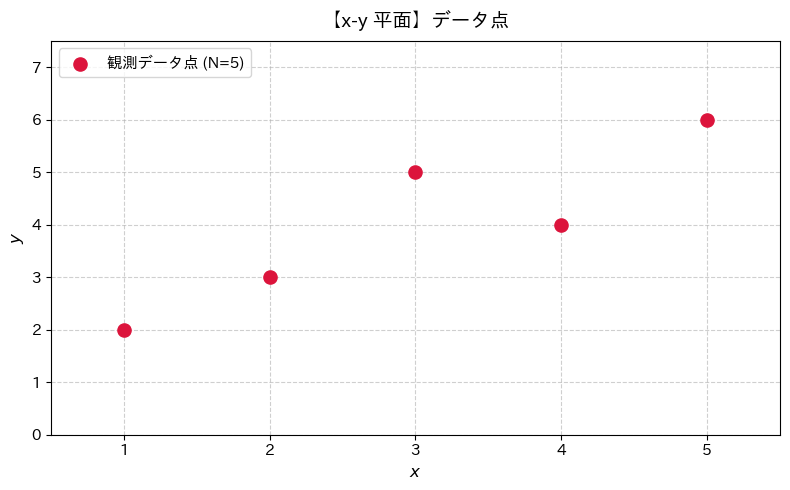

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 5つの観測データ点
x_data = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([2.0, 3.0, 5.0, 4.0, 6.0])
N = len(x_data)

# 単一プロットの作成（figsize は 1 つ分に適したサイズに調整）
fig, ax1 = plt.subplots(figsize=(8, 5))

# x-y 平面（データ点）
ax1.scatter(x_data, y_data, color='crimson', s=90, zorder=5, label='観測データ点 (N=5)')

ax1.set_title('【x-y 平面】データ点', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0.0, 7.5)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.tick_params(labelsize=11)
ax1.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

これらのデータ点に対応する直線モデル：
$$ y = a x + b $$
（$a$: 傾き, $b$: 切片）を引くために、**最小二乗平均二乗誤差（MSE）を目的関数とする最急降下法** を適用します。

#### ■ 目的関数（平均二乗誤差 MSE）
$$
J(a, b) = \frac{1}{2N} \sum_{i=1}^N \bigl( (a x_i + b) - y_i \bigr)^2 \quad (N = 5)
$$

各点での予測誤差（残差）を $e_i = (a x_i + b) - y_i$ と定義すると、パラメータ $a$ および $b$ に関する偏微分（勾配）は次式で与えられます：
$$
\frac{\partial J}{\partial a} = \frac{1}{N} \sum_{i=1}^N e_i x_i = \frac{1}{5} \sum_{i=1}^5 \bigl( (a x_i + b) - y_i \bigr) x_i
$$
$$
\frac{\partial J}{\partial b} = \frac{1}{N} \sum_{i=1}^N e_i = \frac{1}{5} \sum_{i=1}^5 \bigl( (a x_i + b) - y_i \bigr)
$$

#### ■ 最急降下法の更新規則（学習率 $\eta = 0.05$）
$$
\begin{aligned}
a_{k+1} &= a_k - \eta \frac{\partial J}{\partial a} \\
b_{k+1} &= b_k - \eta \frac{\partial J}{\partial b}
\end{aligned}
$$

この演習では、**初期の「$x$ 軸に平行な直線（傾きゼロ）」** から出発し、最急降下法によって 2 ステップにわたりパラメータが最適な直線へと更新されていく計算プロセスを追跡・学習します。


---
### ステップ 0：初期状態（$x$ 軸に平行な直線）

探索の初期値（ステップ $k=0$）として、**$x$ 軸に平行な直線** を設定します：
- 傾き：$a_0 = 0.0$
- 切片：$b_0 = 1.0$
- 初期直線：$y = 0.0 \cdot x + 1.0 = 1.0$

このとき、初期の目的関数値は $J(0.0, 1.0) = 5.50$ です。  
以下のセルを実行して、初期直線の様子（$x$-$y$ 平面）と、誤差曲面上の初期位置（$a$-$b$ 平面）を確認してください。


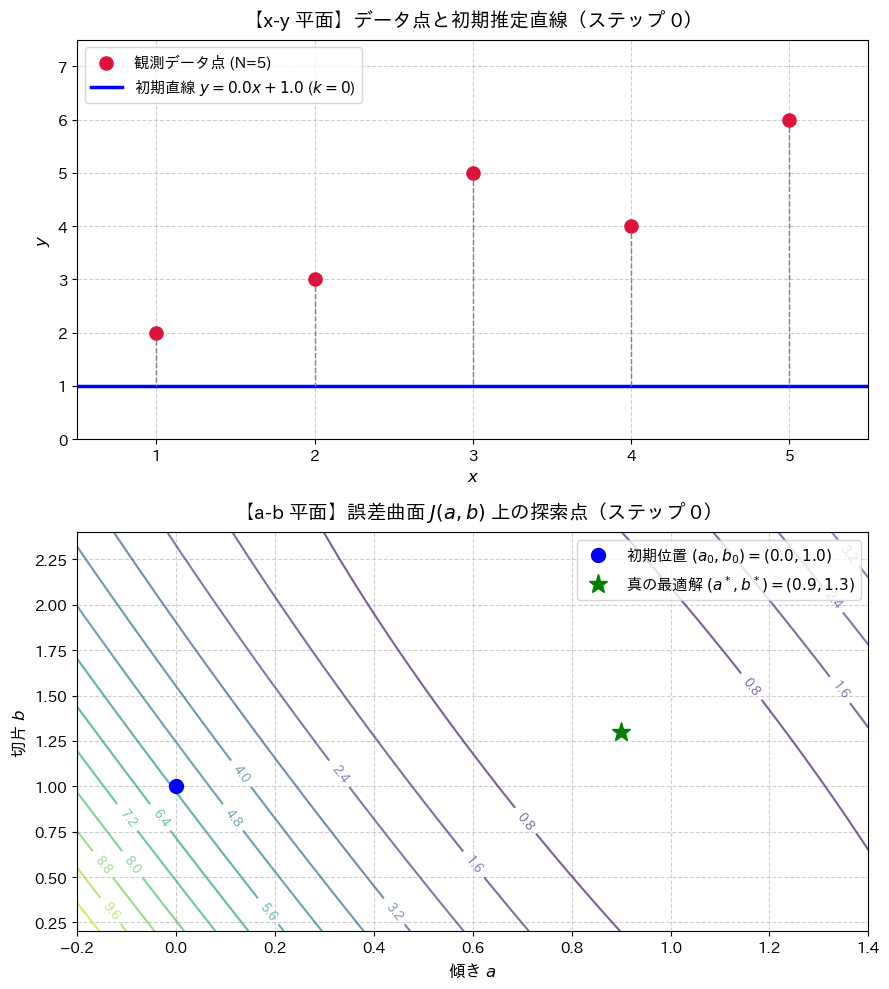

ステップ 0 の状態:
  傾き a0 = 0.0000,  切片 b0 = 1.0000
  目的関数値 (MSE損失) J(a0, b0) = 5.5000


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 5つの観測データ点
x_data = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([2.0, 3.0, 5.0, 4.0, 6.0])
N = len(x_data)

# 目的関数 J(a, b) の定義
def compute_loss(a, b):
    errors = (a * x_data + b) - y_data
    return np.mean(errors**2) / 2.0

# ステップ 0 の初期パラメータ
a0, b0 = 0.0, 1.0
loss0 = compute_loss(a0, b0)

# 解析的最適解（正規方程式）
a_star = 0.9
b_star = 1.3
loss_star = compute_loss(a_star, b_star)

# 縦並びプロットの描画
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))

# 1. 上段：x-y 平面（データ点と初期直線）
ax1.scatter(x_data, y_data, color='crimson', s=90, zorder=5, label='観測データ点 (N=5)')
x_line = np.linspace(0.5, 5.5, 100)
ax1.plot(x_line, a0 * x_line + b0, 'b-', lw=2.5, label=f'初期直線 $y = {a0:.1f}x + {b0:.1f}$ ($k=0$)')

# 各データ点からの残差（誤差）を縦の点線で表示
for xi, yi in zip(x_data, y_data):
    y_pred = a0 * xi + b0
    ax1.plot([xi, xi], [yi, y_pred], 'gray', linestyle='--', lw=1.0)

ax1.set_title('【x-y 平面】データ点と初期推定直線（ステップ 0）', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0.0, 7.5)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.tick_params(labelsize=11)
ax1.legend(fontsize=11, loc='upper left')

# 2. 下段：a-b 平面（誤差曲面 J(a, b) 上の現在地）
a_vals = np.linspace(-0.2, 1.4, 120)
b_vals = np.linspace(0.2, 2.4, 120)
A, B = np.meshgrid(a_vals, b_vals)
Loss_grid = np.zeros_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        Loss_grid[i, j] = compute_loss(A[i, j], B[i, j])

contours = ax2.contour(A, B, Loss_grid, levels=16, cmap='viridis', alpha=0.7)
ax2.clabel(contours, inline=True, fontsize=9)
ax2.plot(a0, b0, 'bo', markersize=10, label=f'初期位置 $(a_0, b_0) = ({a0:.1f}, {b0:.1f})$')
ax2.plot(a_star, b_star, 'g*', markersize=14, label=f'真の最適解 $(a^*, b^*) = ({a_star:.1f}, {b_star:.1f})$')

ax2.set_title('【a-b 平面】誤差曲面 $J(a, b)$ 上の探索点（ステップ 0）', fontsize=14, pad=10)
ax2.set_xlabel('傾き $a$', fontsize=12)
ax2.set_ylabel('切片 $b$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

print(f"ステップ 0 の状態:")
print(f"  傾き a0 = {a0:.4f},  切片 b0 = {b0:.4f}")
print(f"  目的関数値 (MSE損失) J(a0, b0) = {loss0:.4f}")


---
### ステップ 1：手計算による勾配算出と穴埋め課題

初期状態 $a_0 = 0.0, b_0 = 1.0$ から、最急降下法の第 1 ステップの更新を行います。  
学習率は **$\eta = 0.05$** とします。

各点における予測値 $\hat{y}_i = a_0 x_i + b_0 = 1.0$ と、予測誤差 $e_i = \hat{y}_i - y_i$、および傾き勾配への寄与 $e_i x_i$ は以下の通りです：

<div style="overflow-x: auto;">
<table style="white-space: nowrap; border-collapse: collapse; margin-top: 6px; margin-bottom: 6px;">
  <thead>
    <tr style="border-bottom: 2px solid #888;">
      <th style="padding: 5px 6px; text-align: center; white-space: nowrap; width: 38px;">$i$</th>
      <th style="padding: 5px 6px; text-align: center; white-space: nowrap; width: 50px;">$x_i$</th>
      <th style="padding: 5px 6px; text-align: center; white-space: nowrap; width: 50px;">$y_i$</th>
      <th style="padding: 5px 8px; text-align: center; white-space: nowrap; width: 80px;">予測値 $\hat{y}_i$</th>
      <th style="padding: 5px 14px; text-align: center; white-space: nowrap; width: 300px;">誤差 $e_i = \hat{y}_i - y_i$</th>
      <th style="padding: 5px 14px; text-align: center; white-space: nowrap; width: 300px;">$e_i x_i$</th>
    </tr>
  </thead>
  <tbody>
    <tr style="border-bottom: 1px solid #ddd;">
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">1</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">2.0</td>
      <td style="padding: 5px 8px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;">$1.0 - 2.0 = -1.0$</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;">$-1.0 \times 1.0 = -1.0$</td>
    </tr>
    <tr style="border-bottom: 1px solid #ddd;">
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">2</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">2.0</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">3.0</td>
      <td style="padding: 5px 8px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;">$1.0 - 3.0 = -2.0$</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;">$-2.0 \times 2.0 = -4.0$</td>
    </tr>
    <tr style="border-bottom: 1px solid #ddd;">
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">3</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">3.0</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">5.0</td>
      <td style="padding: 5px 8px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;"><b>[ 空欄 A ]</b></td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;"><b>[ 空欄 B ]</b></td>
    </tr>
    <tr style="border-bottom: 1px solid #ddd;">
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">4</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">4.0</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">4.0</td>
      <td style="padding: 5px 8px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;">$1.0 - 4.0 =$ <b>[ 空欄 C ]</b></td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;"><b>[ 空欄 C ]</b> $\times 4.0 =$ <b>[ 空欄 D ]</b></td>
    </tr>
    <tr style="border-bottom: 1px solid #ddd;">
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">5</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">5.0</td>
      <td style="padding: 5px 6px; text-align: center; white-space: nowrap;">6.0</td>
      <td style="padding: 5px 8px; text-align: center; white-space: nowrap;">1.0</td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;"><b>[ 空欄 E ]</b></td>
      <td style="padding: 5px 14px; text-align: center; white-space: nowrap;"><b>[ 空欄 F ]</b></td>
    </tr>
  </tbody>
</table>
</div>

#### ■ 勾配の算出
5 つの誤差の合計：
$$ \sum_{i=1}^5 e_i = (-1.0) + (-2.0) + \text{[空欄 A]} + \text{[空欄 C]} + \text{[空欄 E]} = -15.0 $$
切片に関する勾配：
$$ \frac{\partial J}{\partial b} = \frac{1}{5} \sum_{i=1}^5 e_i = \text{[ 空欄 G ]} $$

重み付き誤差の合計：
$$ \sum_{i=1}^5 e_i x_i = (-1.0) + (-4.0) + \text{[空欄 B]} + \text{[空欄 D]} + \text{[空欄 F]} = -54.0 $$
傾きに関する勾配：
$$ \frac{\partial J}{\partial a} = \frac{1}{5} \sum_{i=1}^5 e_i x_i = \frac{-54.0}{5} = \text{[ 空欄 H ]} $$

#### ■ 最急降下法によるパラメータ更新（$\eta = 0.05$）
$$ a_1 = a_0 - \eta \frac{\partial J}{\partial a} = 0.0 - 0.05 \times \text{[空欄 H]} = \text{[ 空欄 I ]} $$
$$ b_1 = b_0 - \eta \frac{\partial J}{\partial b} = \text{[ 空欄 J ]} $$


## 【解答欄】
（※**このセルをダブルクリック**して、以下の `[ ここに記入 ]` の部分に数値を入力してください）

- **[ 空欄 A: 点3の誤差 $e_3$ ]** = [ ここに記入 ]
- **[ 空欄 B: 点3の積 $e_3 x_3$ ]** = [ ここに記入 ]
- **[ 空欄 C: 点4の誤差 $e_4$ ]** = [ ここに記入 ]
- **[ 空欄 D: 点4の積 $e_4 x_4$ ]** = [ ここに記入 ]
- **[ 空欄 E: 点5の誤差 $e_5$ ]** = [ ここに記入 ]
- **[ 空欄 F: 点5の積 $e_5 x_5$ ]** = [ ここに記入 ]
- **[ 空欄 G: 切片に関する勾配 $\frac{\partial J}{\partial b}$ ]** = [ ここに記入 ]
- **[ 空欄 H: 傾きに関する勾配 $\frac{\partial J}{\partial a}$ ]** = [ ここに記入 ]
- **[ 空欄 I: 更新後の傾き $a_1$ ]** = [ ここに記入 ]
- **[ 空欄 J: 更新後の切片 $b_1$ ]** = [ ここに記入 ]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 5つのデータ点
x_data = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([2.0, 3.0, 5.0, 4.0, 6.0])
eta = 0.05

def compute_loss(a, b):
    errors = (a * x_data + b) - y_data
    return np.mean(errors**2) / 2.0

# ステップ 0
a0, b0 = 0.0, 1.0
e0 = (a0 * x_data + b0) - y_data
grad_a0 = np.mean(e0 * x_data)
grad_b0 = np.mean(e0)

# ステップ 1 の更新
a1 = a0 - eta * grad_a0
b1 = b0 - eta * grad_b0
loss1 = compute_loss(a1, b1)

# 真の最適値
a_star, b_star = 0.9, 1.3

# プロット
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))

# 1. 上段：x-y 平面（ステップ 0 直線 vs ステップ 1 直線）
ax1.scatter(x_data, y_data, color='crimson', s=90, zorder=5, label='観測データ点')
x_line = np.linspace(0.5, 5.5, 100)
ax1.plot(x_line, a0 * x_line + b0, 'gray', linestyle='--', lw=1.8, label=f'初期直線 ($k=0$): $y = {a0:.2f}x + {b0:.2f}$')
ax1.plot(x_line, a1 * x_line + b1, 'b-', lw=2.5, label=f'更新後 ($k=1$): $y = {a1:.2f}x + {b1:.2f}$ (傾きが立ち上がる)')

ax1.set_title('【x-y 平面】第 1 ステップの直線更新（データへ近づく様子）', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0.0, 7.5)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.tick_params(labelsize=11)
ax1.legend(fontsize=11, loc='upper left')

# 2. 下段：a-b 平面（誤差曲面上の移動ステップ 0 -> 1）
a_vals = np.linspace(-0.2, 1.4, 120)
b_vals = np.linspace(0.2, 2.4, 120)
A, B = np.meshgrid(a_vals, b_vals)
Loss_grid = np.zeros_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        Loss_grid[i, j] = compute_loss(A[i, j], B[i, j])

contours = ax2.contour(A, B, Loss_grid, levels=16, cmap='viridis', alpha=0.7)
ax2.clabel(contours, inline=True, fontsize=9)
ax2.plot(a0, b0, 'ro', markersize=8, label='ステップ 0: $(0.0, 1.0)$')
ax2.plot(a1, b1, 'bo', markersize=9, label=f'ステップ 1: $({a1:.2f}, {b1:.2f})$')
ax2.annotate('', xy=(a1, b1), xytext=(a0, b0),
             arrowprops=dict(arrowstyle="->", color="blue", lw=2.0))
ax2.plot(a_star, b_star, 'g*', markersize=14, label='真の最適解 $(0.9, 1.3)$')

ax2.set_title('【a-b 平面】誤差曲面上の移動（ステップ 0 $\\rightarrow$ ステップ 1）', fontsize=14, pad=10)
ax2.set_xlabel('傾き $a$', fontsize=12)
ax2.set_ylabel('切片 $b$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

print(f"第 1 ステップの計算結果:")
print(f"  勾配: ∂J/∂a = {grad_a0:.4f},  ∂J/∂b = {grad_b0:.4f}")
print(f"  更新後: a1 = {a1:.4f},  b1 = {b1:.4f}")
print(f"  MSE損失値: {compute_loss(a0, b0):.4f} --> {loss1:.4f} (損失が大幅に激減！)")


---
### ステップ 2：第 2 ステップの計算プロセス

ステップ 1 で求まった新しい直線 $y = 0.54 x + 1.15$ をもとに、第 2 ステップの勾配計算と更新を行います。

#### ■ 各点での新しい予測誤差 $e_i^{(1)} = (a_1 x_i + b_1) - y_i$:
- 点 1: $(0.54 \times 1.0 + 1.15) - 2.0 = 1.69 - 2.0 = -0.31$
- 点 2: $(0.54 \times 2.0 + 1.15) - 3.0 = 2.23 - 3.0 = -0.77$
- 点 3: $(0.54 \times 3.0 + 1.15) - 5.0 = 2.77 - 5.0 = -2.23$
- 点 4: $(0.54 \times 4.0 + 1.15) - 4.0 = 3.31 - 4.0 = -0.69$
- 点 5: $(0.54 \times 5.0 + 1.15) - 6.0 = 3.85 - 6.0 = -2.15$

#### ■ 新しい勾配の算出:
$$ \sum_{i=1}^5 e_i^{(1)} = (-0.31) + (-0.77) + (-2.23) + (-0.69) + (-2.15) = -6.15 $$
$$ \frac{\partial J}{\partial b} = \frac{-6.15}{5} = -1.23 $$

$$ \sum_{i=1}^5 e_i^{(1)} x_i = (-0.31 \times 1) + (-0.77 \times 2) + (-2.23 \times 3) + (-0.69 \times 4) + (-2.15 \times 5) = -22.05 $$
$$ \frac{\partial J}{\partial a} = \frac{-22.05}{5} = -4.41 $$

#### ■ 第 2 ステップのパラメータ更新（$\eta = 0.05$）:
$$
a_2 = a_1 - \eta \frac{\partial J}{\partial a} = 0.54 - 0.05 \times (-4.41) = 0.54 + 0.2205 = 0.7605
$$
$$
b_2 = b_1 - \eta \frac{\partial J}{\partial b} = 1.15 - 0.05 \times (-1.23) = 1.15 + 0.0615 = 1.2115
$$

目的関数（損失）は、初期の $5.50 \rightarrow 1.076 \rightarrow \mathbf{0.338}$ へと、わずか 2 回の反復で約 94% も削減されました！


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

x_data = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([2.0, 3.0, 5.0, 4.0, 6.0])
eta = 0.05

def compute_loss(a, b):
    errors = (a * x_data + b) - y_data
    return np.mean(errors**2) / 2.0

# ステップ 0
a0, b0 = 0.0, 1.0

# ステップ 1
e0 = (a0 * x_data + b0) - y_data
a1 = a0 - eta * np.mean(e0 * x_data)
b1 = b0 - eta * np.mean(e0)

# ステップ 2
e1 = (a1 * x_data + b1) - y_data
a2 = a1 - eta * np.mean(e1 * x_data)
b2 = b1 - eta * np.mean(e1)

# 真の最適値
a_star, b_star = 0.9, 1.3

# プロット
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))

# 1. 上段：x-y 平面（ステップ 0, 1, 2 直線の推移）
ax1.scatter(x_data, y_data, color='crimson', s=90, zorder=5, label='観測データ点')
x_line = np.linspace(0.5, 5.5, 100)
ax1.plot(x_line, a0 * x_line + b0, color='gray', linestyle='--', lw=1.5, label=f'k=0: $y = {a0:.2f}x + {b0:.2f}$ (初期直線)')
ax1.plot(x_line, a1 * x_line + b1, color='orange', linestyle='--', lw=2.0, label=f'k=1: $y = {a1:.2f}x + {b1:.2f}$')
ax1.plot(x_line, a2 * x_line + b2, color='forestgreen', linestyle='-', lw=2.5, label=f'k=2: $y = {a2:.2f}x + {b2:.2f}$')
ax1.plot(x_line, a_star * x_line + b_star, color='black', linestyle=':', lw=2.0, label=f'真の最適直線: $y = {a_star:.1f}x + {b_star:.1f}$')

ax1.set_title('【x-y 平面】第 2 ステップまでの直線フィッティング推移', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0.0, 7.5)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.tick_params(labelsize=11)
ax1.legend(fontsize=10, loc='upper left')

# 2. 下段：a-b 平面（2ステップの探索軌跡）
a_vals = np.linspace(-0.2, 1.4, 120)
b_vals = np.linspace(0.2, 2.4, 120)
A, B = np.meshgrid(a_vals, b_vals)
Loss_grid = np.zeros_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        Loss_grid[i, j] = compute_loss(A[i, j], B[i, j])

contours = ax2.contour(A, B, Loss_grid, levels=16, cmap='viridis', alpha=0.7)
ax2.clabel(contours, inline=True, fontsize=9)
ax2.plot([a0, a1, a2], [b0, b1, b2], 'r-o', lw=2.0, markersize=7, label='降下軌跡 $(a_0, b_0) \\rightarrow (a_1, b_1) \\rightarrow (a_2, b_2)$')
ax2.plot(a_star, b_star, 'g*', markersize=14, label=f'最適解 $(a^*, b^*) = ({a_star:.1f}, {b_star:.1f})$')

# 矢印
ax2.annotate('', xy=(a1, b1), xytext=(a0, b0), arrowprops=dict(arrowstyle="->", color="red", lw=1.8))
ax2.annotate('', xy=(a2, b2), xytext=(a1, b1), arrowprops=dict(arrowstyle="->", color="red", lw=1.8))

ax2.set_title('【a-b 平面】誤差曲面上を最小値へ向かって進む軌跡', fontsize=14, pad=10)
ax2.set_xlabel('傾き $a$', fontsize=12)
ax2.set_ylabel('切片 $b$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

print(f"第 2 ステップ終了後のパラメータ:")
print(f"  a2 = {a2:.4f} (目標 0.9 に急接近)")
print(f"  b2 = {b2:.4f} (目標 1.3 に急接近)")
print(f"  MSE損失値: {compute_loss(a2, b2):.4f}")


---
### 20 ステップまでの連続更新と完全収束の確認

さらに反復を継続すると、パラメータ $(a_k, b_k)$ がどのように真の最適直線（正規方程式による解析解 $y = 0.9x + 1.3$）に吸い寄せられていくかをプログラムで確認してみましょう。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

x_data = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_data = np.array([2.0, 3.0, 5.0, 4.0, 6.0])
eta = 0.05
steps = 20

def compute_loss(a, b):
    errors = (a * x_data + b) - y_data
    return np.mean(errors**2) / 2.0

a, b = 0.0, 1.0
traj_a = [a]
traj_b = [b]
losses = [compute_loss(a, b)]

for k in range(steps):
    err = (a * x_data + b) - y_data
    ga = np.mean(err * x_data)
    gb = np.mean(err)
    a = a - eta * ga
    b = b - eta * gb
    traj_a.append(a)
    traj_b.append(b)
    losses.append(compute_loss(a, b))

a_star, b_star = 0.9, 1.3

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 10))

# 1. 上段：x-y 平面でのフィッティング最終直線
ax1.scatter(x_data, y_data, color='crimson', s=90, zorder=5, label='観測データ点')
x_line = np.linspace(0.5, 5.5, 100)
ax1.plot(x_line, traj_a[0] * x_line + traj_b[0], color='gray', linestyle='--', lw=1.5, label='初期直線 ($k=0$)')
ax1.plot(x_line, traj_a[1] * x_line + traj_b[1], color='orange', linestyle='--', lw=1.5, label='反復途中 ($k=1$)')
ax1.plot(x_line, traj_a[2] * x_line + traj_b[2], color='blue', linestyle='--', lw=1.5, label='反復途中 ($k=2$)')
ax1.plot(x_line, a * x_line + b, color='green', linestyle='-', lw=2.5, label=f'最終直線 ($k=20$): $y = {a:.2f}x + {b:.2f}$')
ax1.plot(x_line, a_star * x_line + b_star, color='black', linestyle=':', lw=2.0, label=f'解析的最適解: $y = {a_star:.1f}x + {b_star:.1f}$')

ax1.set_title('【x-y 平面】20 ステップにおける直線の完全収束', fontsize=14, pad=10)
ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0.0, 7.5)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.tick_params(labelsize=11)
ax1.legend(fontsize=10, loc='upper left')

# 2. 下段：a-b 平面での軌跡全体の収束
a_vals = np.linspace(-0.2, 1.4, 120)
b_vals = np.linspace(0.2, 2.4, 120)
A, B = np.meshgrid(a_vals, b_vals)
Loss_grid = np.zeros_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        Loss_grid[i, j] = compute_loss(A[i, j], B[i, j])

contours = ax2.contour(A, B, Loss_grid, levels=16, cmap='viridis', alpha=0.7)
ax2.clabel(contours, inline=True, fontsize=9)
ax2.plot(traj_a, traj_b, 'r-o', lw=1.8, markersize=5, label='最急降下法の探索軌跡 (20ステップ)')
ax2.plot(a_star, b_star, 'g*', markersize=14, label=f'最適解 $(a^*, b^*) = ({a_star:.1f}, {b_star:.1f})$')

ax2.set_title('【a-b 平面】誤差曲面の中心（最小値）への収束軌跡', fontsize=14, pad=10)
ax2.set_xlabel('傾き $a$', fontsize=12)
ax2.set_ylabel('切片 $b$', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

print(f"20ステップ後の最適化結果:")
print(f"  最急降下法の解 : a = {a:.4f},  b = {b:.4f},  MSE損失 = {losses[-1]:.4f}")
print(f"  解析的最適解   : a = {a_star:.4f},  b = {b_star:.4f},  MSE損失 = {compute_loss(a_star, b_star):.4f}")
